# YOLOv8n Baseline Evaluation, Dataset V2
## Overview
This notebook evaluates the saved YOLOv8n baseline on the cleaned Dataset V2 test split.
## Method
1.   Prepare Dataset V2 using the shared cleaning module.
2.   Check the split counts and preparation record.
3.   Load the saved YOLOv8n baseline weights.
4.   Measure precision, recall, mAP50 and mAP50–95 on the test split.
## Files
*   Dataset: dataset/pork_rasher_v2.zip
*   Weights: yolov8n_v2_baseline/weights/best.pt
*   Output: test metrics and confusion-matrix plots
## Limitations
Source overlap is checked using `.rf.` filename identifiers, so differently named copies may not be detected. Dataset V2 contains four classes, and the test set has only four twisted-meat annotations. The small class sample limits conclusions about twisted-meat performance.






In [ ]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from pathlib import Path
import sys

# Dataset and saved model folders.
PROJECT_ROOT = Path("/content/drive/MyDrive/MMA3001_v2_folder")
ZIP_PATH = PROJECT_ROOT / "dataset" / "pork_rasher_v2.zip"
CLEAN_DIR = Path("/content/pork_rasher_dataset_v2_clean")
MANIFEST_PATH = PROJECT_ROOT / "dataset" / "manifests" / "v2_preparation.json"
RUNS_DIR = PROJECT_ROOT / "model_runs"
ORIGINAL_RUNS_DIR = Path("/content/drive/MyDrive/MMA3001_Project/model_runs")

# Find the shared cleaning code.
module_candidates = [
    Path.cwd() / "src",
    Path("/content/src"),
    Path("/content"),
    PROJECT_ROOT / "src",
    Path("/content/drive/MyDrive/MMA3001_v4_Project/src"),
]
module_candidates += sorted(Path("/content").glob("*/src"))
module_dir = next((p for p in module_candidates
                   if (p / "dataset_preparation.py").is_file()), None)
if module_dir is None:
    raise FileNotFoundError(
        "dataset_preparation.py not found. Copy it to the V2 project's src folder "
        "or use a cloned GitHub repository in /content/."
    )
sys.path.insert(0, str(module_dir))
from dataset_preparation import prepare_dataset, print_audit, assert_preparations_match

In [ ]:
# Clean source overlaps using the shared module.
manifest = prepare_dataset(
    zip_path=ZIP_PATH,
    output_dir=CLEAN_DIR,
    expected_dataset_version=2,
    require_labels=True,
)
print("Cross-split overlaps removed:", manifest["removed_overlap_images"])
print_audit(manifest["audit"])

Cross-split overlaps removed: {'train': 9, 'valid': 1}

TRAIN: 1935 images; 362 backgrounds; 0 missing label files
  loose-meat: 65 boxes
  packaging-error: 521 boxes
  twisted-meat: 67 boxes
  unsealed: 1045 boxes

VALID: 119 images; 14 backgrounds; 0 missing label files
  loose-meat: 3 boxes
  packaging-error: 34 boxes
  twisted-meat: 3 boxes
  unsealed: 80 boxes

TEST: 80 images; 12 backgrounds; 0 missing label files
  loose-meat: 3 boxes
  packaging-error: 23 boxes
  twisted-meat: 4 boxes
  unsealed: 49 boxes


In [ ]:
# Check the original V2 split counts and class order.
EXPECTED_IMAGES = {"train": 1935, "valid": 119, "test": 80}
EXPECTED_CLASSES = ["loose-meat", "packaging-error", "twisted-meat", "unsealed"]
actual_images = {s: d["images"] for s, d in manifest["audit"]["splits"].items()}
assert actual_images == EXPECTED_IMAGES, (actual_images, EXPECTED_IMAGES)
assert manifest["audit"]["class_names"] == EXPECTED_CLASSES
assert manifest["moved_to_validation"] == 0
print("V2 split counts and class order verified.")
print("Split fingerprint:", manifest["split_fingerprint_sha256"])

V2 split counts and class order verified.
Split fingerprint: 37574f1f67a94a0aa532cce668ed5c0e8c53b0629191a967498d2d3b8d42e711


In [ ]:
# Check the cleaned split against the saved preparation record.
if MANIFEST_PATH.exists():
    assert_preparations_match(manifest, MANIFEST_PATH)
    print("Preparation record matches.")
else:
    print("No prior preparation record was found. Split counts were verified, ")
    print("but the original training run did not save a preparation manifest.")

Preparation record matches.


In [ ]:
%pip install -q ultralytics
from ultralytics import YOLO

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 40.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 11.9 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


In [ ]:
# The original training and validation notebooks used different Drive roots.
weight_candidates = [
    RUNS_DIR / "yolov8n_v2_baseline" / "weights" / "best.pt",
    ORIGINAL_RUNS_DIR / "yolov8n_v2_baseline" / "weights" / "best.pt",
]
BASELINE_WEIGHTS = next((p for p in weight_candidates if p.is_file()), None)
if BASELINE_WEIGHTS is None:
    raise FileNotFoundError(
        "V2 baseline weights not found. Checked:\n" +
        "\n".join(str(p) for p in weight_candidates)
    )
print("Baseline weights:", BASELINE_WEIGHTS)

Baseline weights: /content/drive/MyDrive/MMA3001_v2_folder/model_runs/yolov8n_v2_baseline/weights/best.pt


In [ ]:
# Check that the saved model uses the same four classes.
model = YOLO(str(BASELINE_WEIGHTS))
model_classes = model.names
if isinstance(model_classes, dict):
    model_classes = [model_classes[k] for k in sorted(model_classes)]
if list(model_classes) != manifest["audit"]["class_names"]:
    raise ValueError("Model class order differs from Dataset V2.")
print("Class order:", model_classes)

Class order: ['loose-meat', 'packaging-error', 'twisted-meat', 'unsealed']


In [ ]:
# Evaluate the held-out test split.
test_results = model.val(
    data=str(CLEAN_DIR / "data.yaml"),
    split="test",
    imgsz=640,
    batch=16,
    device=0,
    plots=True,
    project=str(RUNS_DIR),
    name="yolov8n_v2_baseline_test",
)
print(f"Precision: {test_results.box.mp:.4f}")
print(f"Recall: {test_results.box.mr:.4f}")
print(f"mAP50: {test_results.box.map50:.4f}")
print(f"mAP50–95: {test_results.box.map:.4f}")
print("Evaluation output:", test_results.save_dir)

Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 3,006,428 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1718.7±493.2 MB/s, size: 65.8 KB)
val: Scanning /content/pork_rasher_dataset_v2_clean/test/labels... 80 images, 12 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 80/80 1.2Kit/s 0.1s
val: New cache created: /content/pork_rasher_dataset_v2_clean/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 2.3it/s 2.2s
                   all         80         79      0.775      0.439      0.499      0.243
            loose-meat          2          3       0.72      0.333      0.555      0.218
       packaging-error         16         23      0.581      0.609      0.554      0.176
          twisted-meat          4          4          1          0     0.0305    0.00659
              unsealed         49         49    

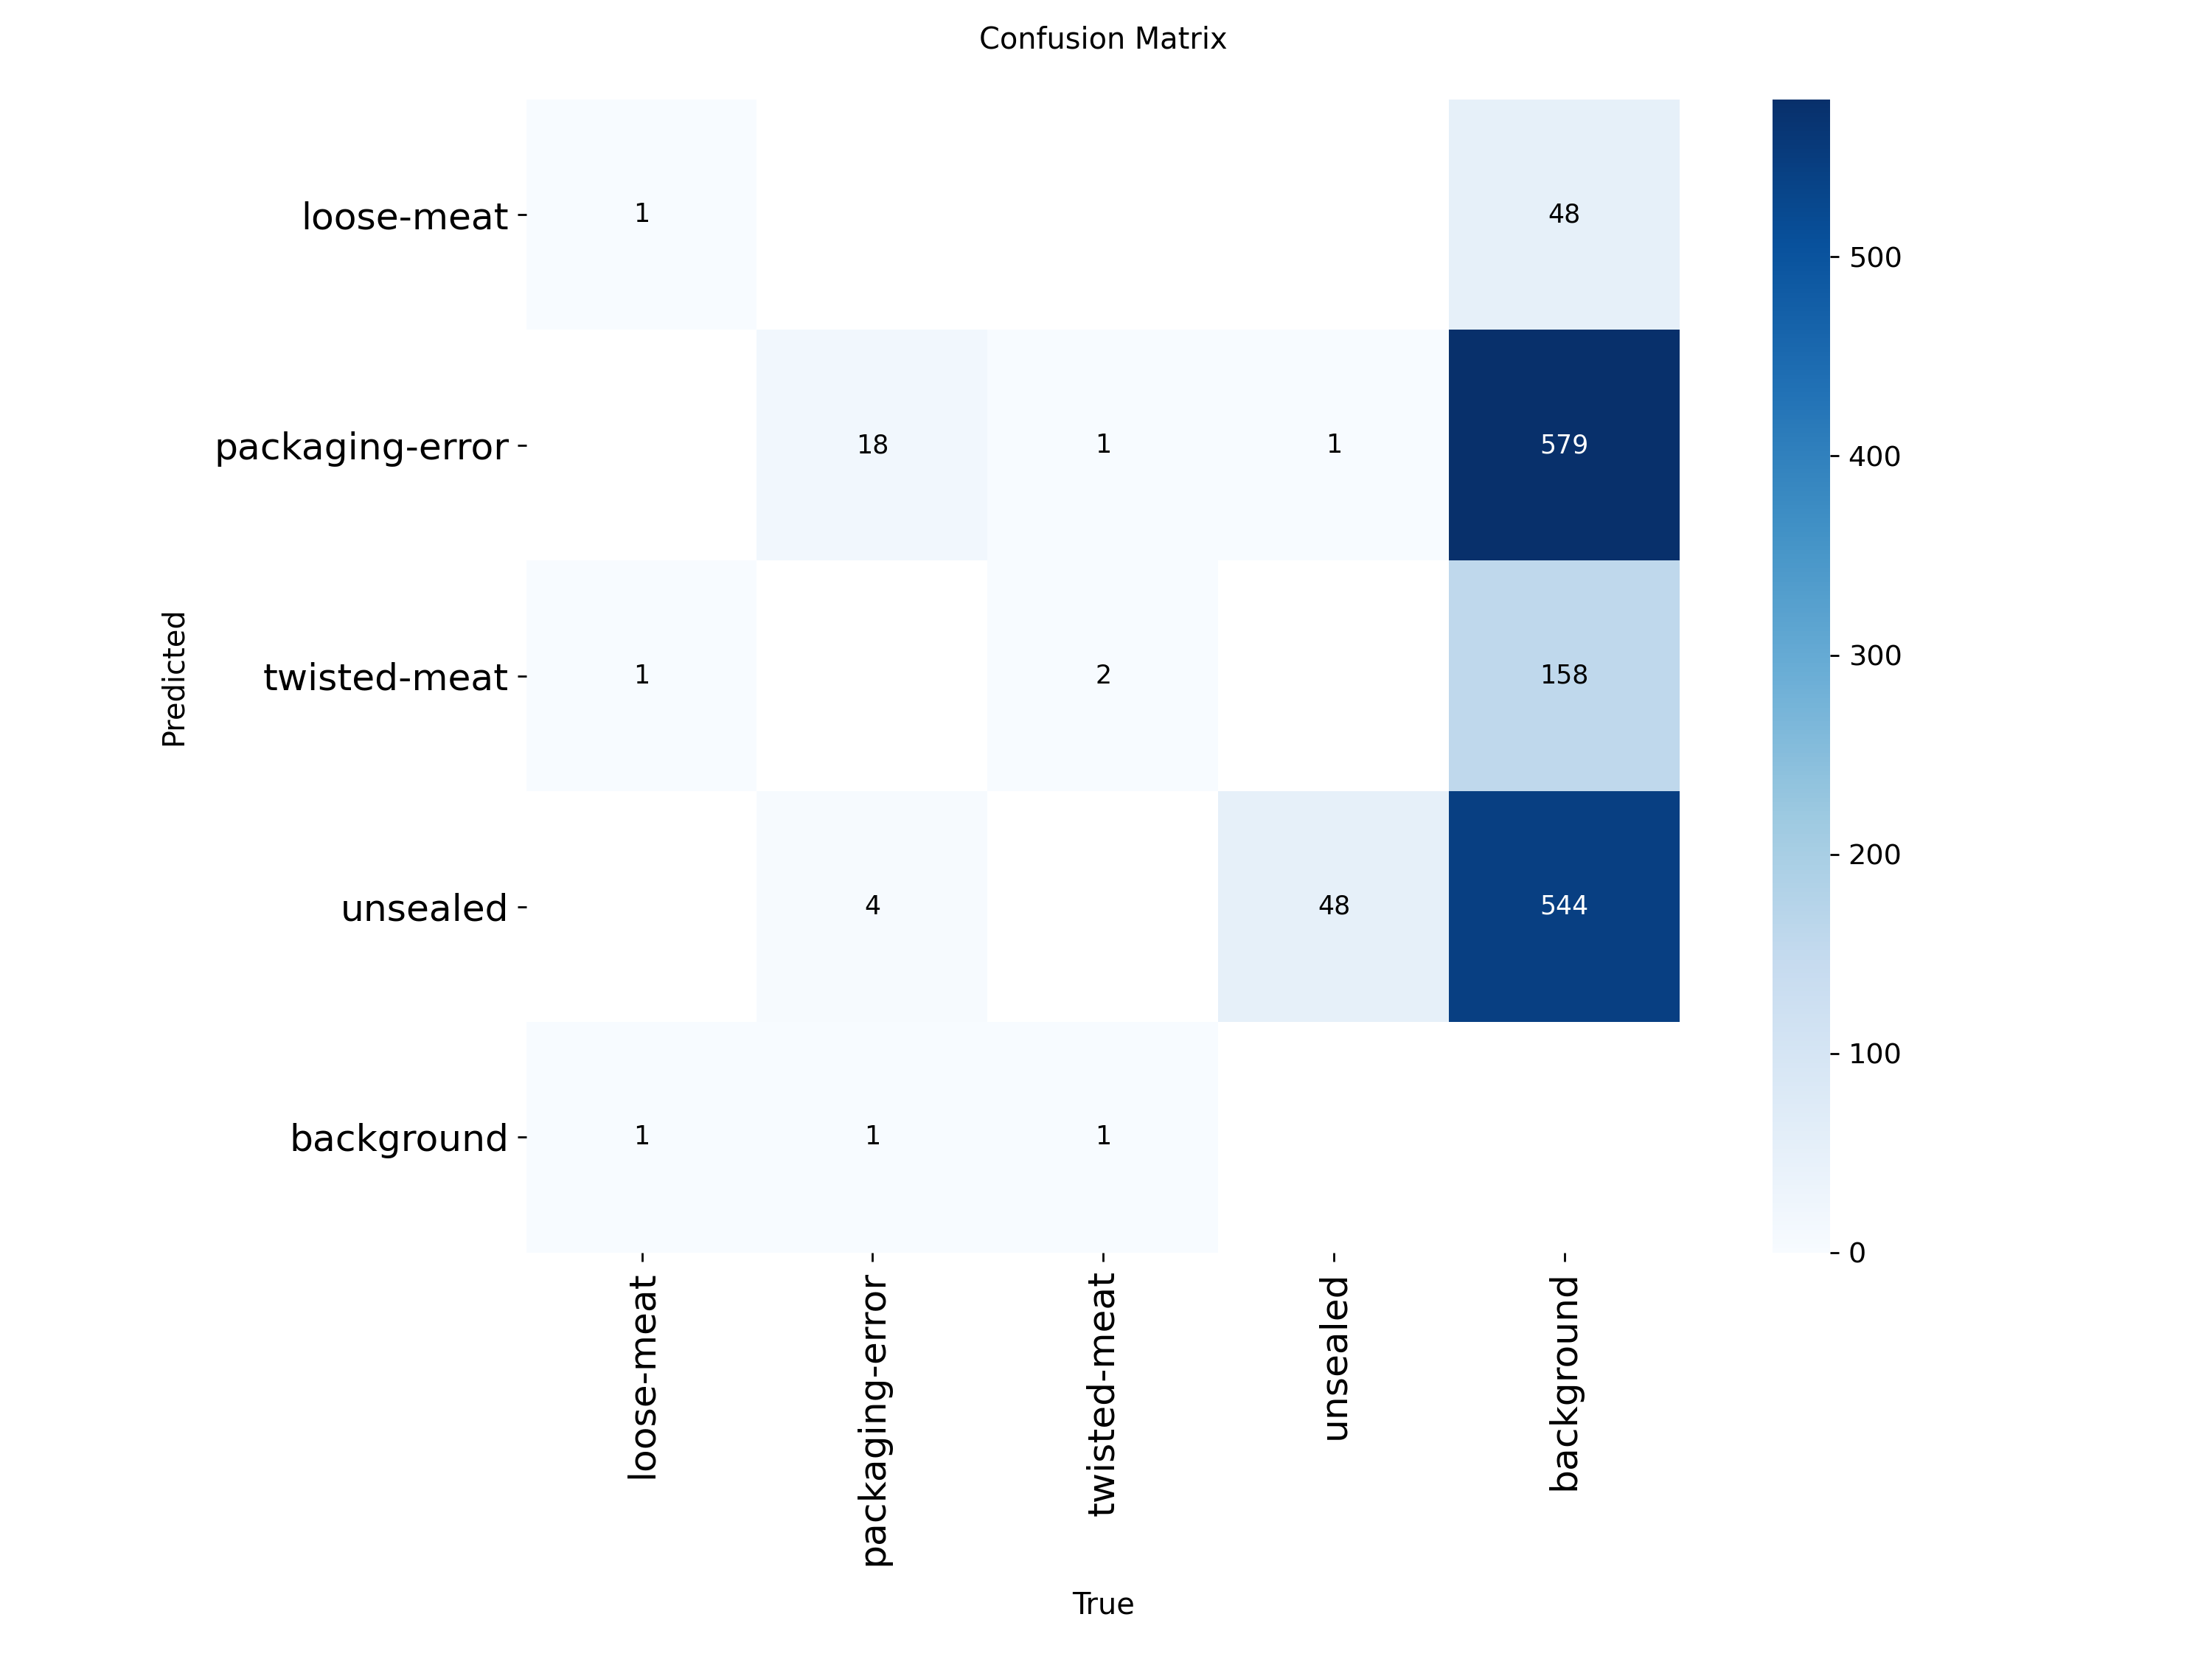

In [ ]:
from IPython.display import display
from PIL import Image

# Show the confusion matrix from this test evaluation.
confusion_path = Path(test_results.save_dir) / "confusion_matrix.png"
if confusion_path.is_file():
    display(Image.open(confusion_path))
else:
    print("Confusion matrix not found:", confusion_path)

## Results
The completed V2 baseline test evaluation reported 77.52% precision, 43.92% recall, 49.85% mAP50 and 24.34% mAP50–95 on 80 test images with 79 labelled defect instances.